# 3 · Problem 1 — does legal pretraining help?

BERT against Legal-BERT. They share an architecture, a parameter count, a context
window and a chunk width, and differ only in pretraining corpus, so any gap between
them is attributable to domain adaptation.

**Needs a GPU.** About an hour on a T4 for the main runs, then about 20 minutes per
extra seed. Every evaluation prints a classification report.

## Setup

Clone the repository and install. The data layer needs nothing beyond the standard
library, so this is only for the model code.


In [1]:
# Safe to re-run in the same session: clones once, then pulls, and always works from
# $ROOT/NNDL. Re-running a plain `git clone` + `%cd NNDL` used to nest a second
# copy inside the first.
import os, sys
# Colab works in /content, Kaggle in /kaggle/working; everything else is the same.
ROOT = '/kaggle/working' if os.path.isdir('/kaggle/working') else '/content'
%cd $ROOT
!test -d NNDL || git clone -q https://github.com/ManasDasri/NNDL.git
%cd $ROOT/NNDL
!git pull -q
!pip install -q -e . 'matplotlib>=3.8'
# pip -e registers the package when Python starts, so this already-running kernel
# can't see it yet; the command-line tools can. Point the kernel at the source.
sys.path.insert(0, f'{ROOT}/NNDL/src')

import torch
if not torch.cuda.is_available():
    raise RuntimeError('No GPU, so training would take many hours. Colab: Runtime > Change runtime type > T4 GPU. '
                       'Kaggle: Settings > Accelerator > GPU T4 x2, and turn Internet on. Then run all.')
print('GPU:', torch.cuda.get_device_name(0))

/kaggle/working
/kaggle/working/NNDL
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for legal-risk-clause-classifier (pyproject.toml) ... done
GPU: Tesla T4


### Prepare the corpus

Extracts answer spans from `CUAD_v1.json` and assigns document-level splits.
Chunking happens at training time, because each model needs a different window.


In [2]:
!legal-risk-prepare --cuad_json data/CUAD_v1.json --out_dir data/processed


510 documents -> data/processed/documents.jsonl
splits {'train': 358, 'val': 76, 'test': 76} -> data/processed/splits.json
  Cap on Liability                   662 spans across  275 documents
  Non-Compete                        251 spans across  119 documents
  License Grant                      772 spans across  255 documents
  Audit Rights                       639 spans across  214 documents
  Termination for Convenience        245 spans across  183 documents
  Insurance                          554 spans across  166 documents


### The baseline first

The comparison needs a floor to read against, and the CNN trains in a couple of
minutes on a GPU. Without it the table below has nothing to say about whether
110M pretrained parameters are earning their cost.


In [3]:
!legal-risk-train-cnn --epochs 12 --batch_size 32 --output_dir outputs/cnn


{'train': 13829, 'val': 2905, 'test': 3314}
vocabulary: 30,968 types
pos_weight: 27x, 68x, 22x, 35x, 63x, 53x
mixed precision: on (float16)
{"epoch": 1, "train_loss": 1.2099131107261494, "val_macro_f1": 0.4465317626905958, "val_macro_average_precision": 0.5832966549722397}
{"epoch": 2, "train_loss": 0.807016679272916, "val_macro_f1": 0.547814581213376, "val_macro_average_precision": 0.6127912297054824}
{"epoch": 3, "train_loss": 0.7040155278067115, "val_macro_f1": 0.5324138661277763, "val_macro_average_precision": 0.6309930973031311}
{"epoch": 4, "train_loss": 0.6363410720726428, "val_macro_f1": 0.520120959840309, "val_macro_average_precision": 0.647453384599426}
{"epoch": 5, "train_loss": 0.5411750470991429, "val_macro_f1": 0.5575492141137508, "val_macro_average_precision": 0.6738551230159219}
{"epoch": 6, "train_loss": 0.4998710772095734, "val_macro_f1": 0.6251464720296448, "val_macro_average_precision": 0.6696035285328111}
{"epoch": 7, "train_loss": 0.4138947072187245, "val_macro_f1

### Train both

Identical settings. The only difference is the checkpoint.


In [4]:
!legal-risk-train-transformer --model bert       --epochs 3 --batch_size 16 --lr 2e-5 --output_dir outputs/bert


bert-base-uncased  window=300w overlap=100w max_length=512t
{'train': 13829, 'val': 2905, 'test': 3314}
config.json: 100%|█████████████████████████████| 570/570 [00:00<00:00, 2.19MB/s]
tokenizer_config.json: 100%|██████████████████| 48.0/48.0 [00:00<00:00, 211kB/s]
vocab.txt: 100%|█████████████████████████████| 232k/232k [00:00<00:00, 6.23MB/s]
tokenizer.json: 100%|████████████████████████| 466k/466k [00:00<00:00, 15.6MB/s]

model.safetensors: downloading bytes: █████████▍            |  190MB, 12.9MB/s  
model.safetensors: downloading bytes: ███████████▊          |  238MB, 18.5MB/s  
model.safetensors: downloading bytes: ████████████████████▏ |  404MB, 34.0MB/s  
model.safetensors: downloading bytes: ██████████████████████|  415MB, 38.8MB/s  
model.safetensors: reconstructing file: 100%|██████|  440MB /  440MB, 41.8MB/s  
Loading weights: 100%|██████████████████████| 199/199 [00:00<00:00, 2579.14it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key 

In [5]:
!legal-risk-train-transformer --model legal-bert --epochs 3 --batch_size 16 --lr 2e-5 --output_dir outputs/legal_bert


nlpaueb/legal-bert-base-uncased  window=300w overlap=100w max_length=512t
{'train': 13829, 'val': 2905, 'test': 3314}
config.json: 100%|█████████████████████████| 1.02k/1.02k [00:00<00:00, 99.7kB/s]
tokenizer_config.json: 100%|██████████████████| 48.0/48.0 [00:00<00:00, 229kB/s]
vocab.txt: 100%|█████████████████████████████| 222k/222k [00:00<00:00, 8.33MB/s]
special_tokens_map.json: 100%|██████████████████| 112/112 [00:00<00:00, 749kB/s]
[transformers] You passed `num_labels=6` which is incompatible to the `id2label` map of length `2`.

pytorch_model.bin: downloading bytes: █████████▉            |  198MB, 14.6MB/s  
pytorch_model.bin: downloading bytes: █████████████▎        |  266MB, 22.0MB/s  
pytorch_model.bin: downloading bytes: ████████████████▊     |  338MB, 27.6MB/s  
pytorch_model.bin: downloading bytes: ███████████████████▊  |  396MB, 34.8MB/s  
pytorch_model.bin: downloading bytes: ██████████████████████|  415MB, 38.1MB/s  
pytorch_model.bin: reconstructing file: 100%|██████|

### Evaluate on the same held-out contracts


In [6]:
for run in ('outputs/cnn', 'outputs/bert', 'outputs/legal_bert'):
    !legal-risk-evaluate --run_dir {run} --split test

pooling: noisy_or  (validation macro AP 0.886)
textcnn  test  (3314 chunks, 76 documents)
  chunk    macro F1 0.639  AP 0.691
  document macro F1 0.829  AP 0.896  [noisy_or ]
  -> outputs/cnn/evaluation_test.json
  -> outputs/cnn/classification_report_test.txt

textcnn · test split

Window level (3314 windows of 300 words, validation-tuned thresholds)

                             precision    recall  f1-score   support

           Cap on Liability      0.784     0.731     0.756       104
                Non-Compete      0.516     0.281     0.364        57
              License Grant      0.700     0.815     0.753       146
               Audit Rights      0.547     0.874     0.673        87
Termination for Convenience      0.462     0.480     0.471        50
                  Insurance      0.797     0.843     0.819        70

                  micro avg      0.657     0.720     0.687       514
                  macro avg      0.634     0.670     0.639       514
               weighte

### Read the per-class columns, not the macro score

The hypothesis is specific: Legal-BERT should gain most on labels carried by legal
vocabulary, and least on labels carried by ordinary English such as Insurance.
A uniform gain across all six would mean something other than domain knowledge is
responsible.


In [7]:
import json, pathlib

# Only compare runs that actually exist, so a missing one narrows the table
# instead of crashing after an hour of training.
CANDIDATES = (('CNN', 'cnn'), ('BERT', 'bert'), ('Legal-BERT', 'legal_bert'), ('Longformer', 'longformer'))
runs = {}
for name, directory in CANDIDATES:
    path = pathlib.Path('outputs') / directory / 'metrics.json'
    if path.exists():
        runs[name] = json.load(open(path))
    else:
        print(f'skipping {name}: no {path}')

assert runs, 'no finished runs found'
labels = [r['label'] for r in next(iter(runs.values()))['test_at_tuned_thresholds']['per_class']]

print(f"\n{'label':32s}" + ''.join(f'{n:>13s}' for n in runs))
for i, label in enumerate(labels):
    f1 = {n: r['test_at_tuned_thresholds']['per_class'][i]['f1'] for n, r in runs.items()}
    row = f"{label:32s}" + ''.join(f'{f1[n]:13.3f}' for n in runs)
    if 'BERT' in f1 and 'Legal-BERT' in f1:
        row += f"   Δ {f1['Legal-BERT'] - f1['BERT']:+.3f}"
    print(row)

macro = {n: r['test_at_tuned_thresholds']['macro_f1'] for n, r in runs.items()}
row = f"\n{'macro F1':32s}" + ''.join(f'{macro[n]:13.3f}' for n in runs)
if 'BERT' in macro and 'Legal-BERT' in macro:
    row += f"   Δ {macro['Legal-BERT'] - macro['BERT']:+.3f}"
print(row)


skipping Longformer: no outputs/longformer/metrics.json

label                                     CNN         BERT   Legal-BERT
Cap on Liability                        0.756        0.722        0.811   Δ +0.089
Non-Compete                             0.364        0.535        0.529   Δ -0.006
License Grant                           0.753        0.665        0.795   Δ +0.130
Audit Rights                            0.673        0.728        0.739   Δ +0.011
Termination for Convenience             0.471        0.645        0.723   Δ +0.078
Insurance                               0.819        0.871        0.838   Δ -0.033

macro F1                                0.639        0.694        0.739   Δ +0.045


### Before claiming a result

Run-to-run variance on identical settings is about **±0.03 macro F1**, from float
nondeterminism on GPU. A gap smaller than that is noise.

If the difference is under 0.03, rerun both across several seeds and report the
spread. The honest finding may be *"domain pretraining did not measurably help on
this task at this scale"* — which is a real result, and more interesting than a
margin inside the noise floor.


In [8]:
# Extra seeds, with the same settings as the main runs. BERT has seeds 42 and 1 from
# the first run of this notebook; Legal-BERT only 42. These give both three seeds.
for seed in (1, 2):
    for model, out in (('bert', 'bert'), ('legal-bert', 'legal_bert')):
        run = f'outputs/{out}_s{seed}'
        !legal-risk-train-transformer --model {model} --epochs 3 --batch_size 16 --lr 2e-5 --seed {seed} --output_dir {run}
        !legal-risk-evaluate --run_dir {run} --split test

bert-base-uncased  window=300w overlap=100w max_length=512t
{'train': 13829, 'val': 2905, 'test': 3314}
Loading weights: 100%|██████████████████████| 199/199 [00:00<00:00, 2777.31it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; n

### Classification reports and plots

For every evaluated run: its classification report, a confusion matrix per label at
window and contract level, and precision, recall, F1 and accuracy by label. The last
chart compares every run at contract level.

bert · test split

Window level (3314 windows of 300 words, validation-tuned thresholds)

                             precision    recall  f1-score   support

           Cap on Liability      0.635     0.837     0.722       104
                Non-Compete      0.486     0.596     0.535        57
              License Grant      0.524     0.911     0.665       146
               Audit Rights      0.630     0.862     0.728        87
Termination for Convenience      0.541     0.800     0.645        50
                  Insurance      0.831     0.914     0.871        70

                  micro avg      0.592     0.842     0.696       514
                  macro avg      0.608     0.820     0.694       514
               weighted avg      0.604     0.842     0.699       514
                samples avg      0.126     0.124     0.124       514
Samples avg scores each window over its own labels, so the many windows with no
clause count as zero here. Read the per-class rows and the macro aver

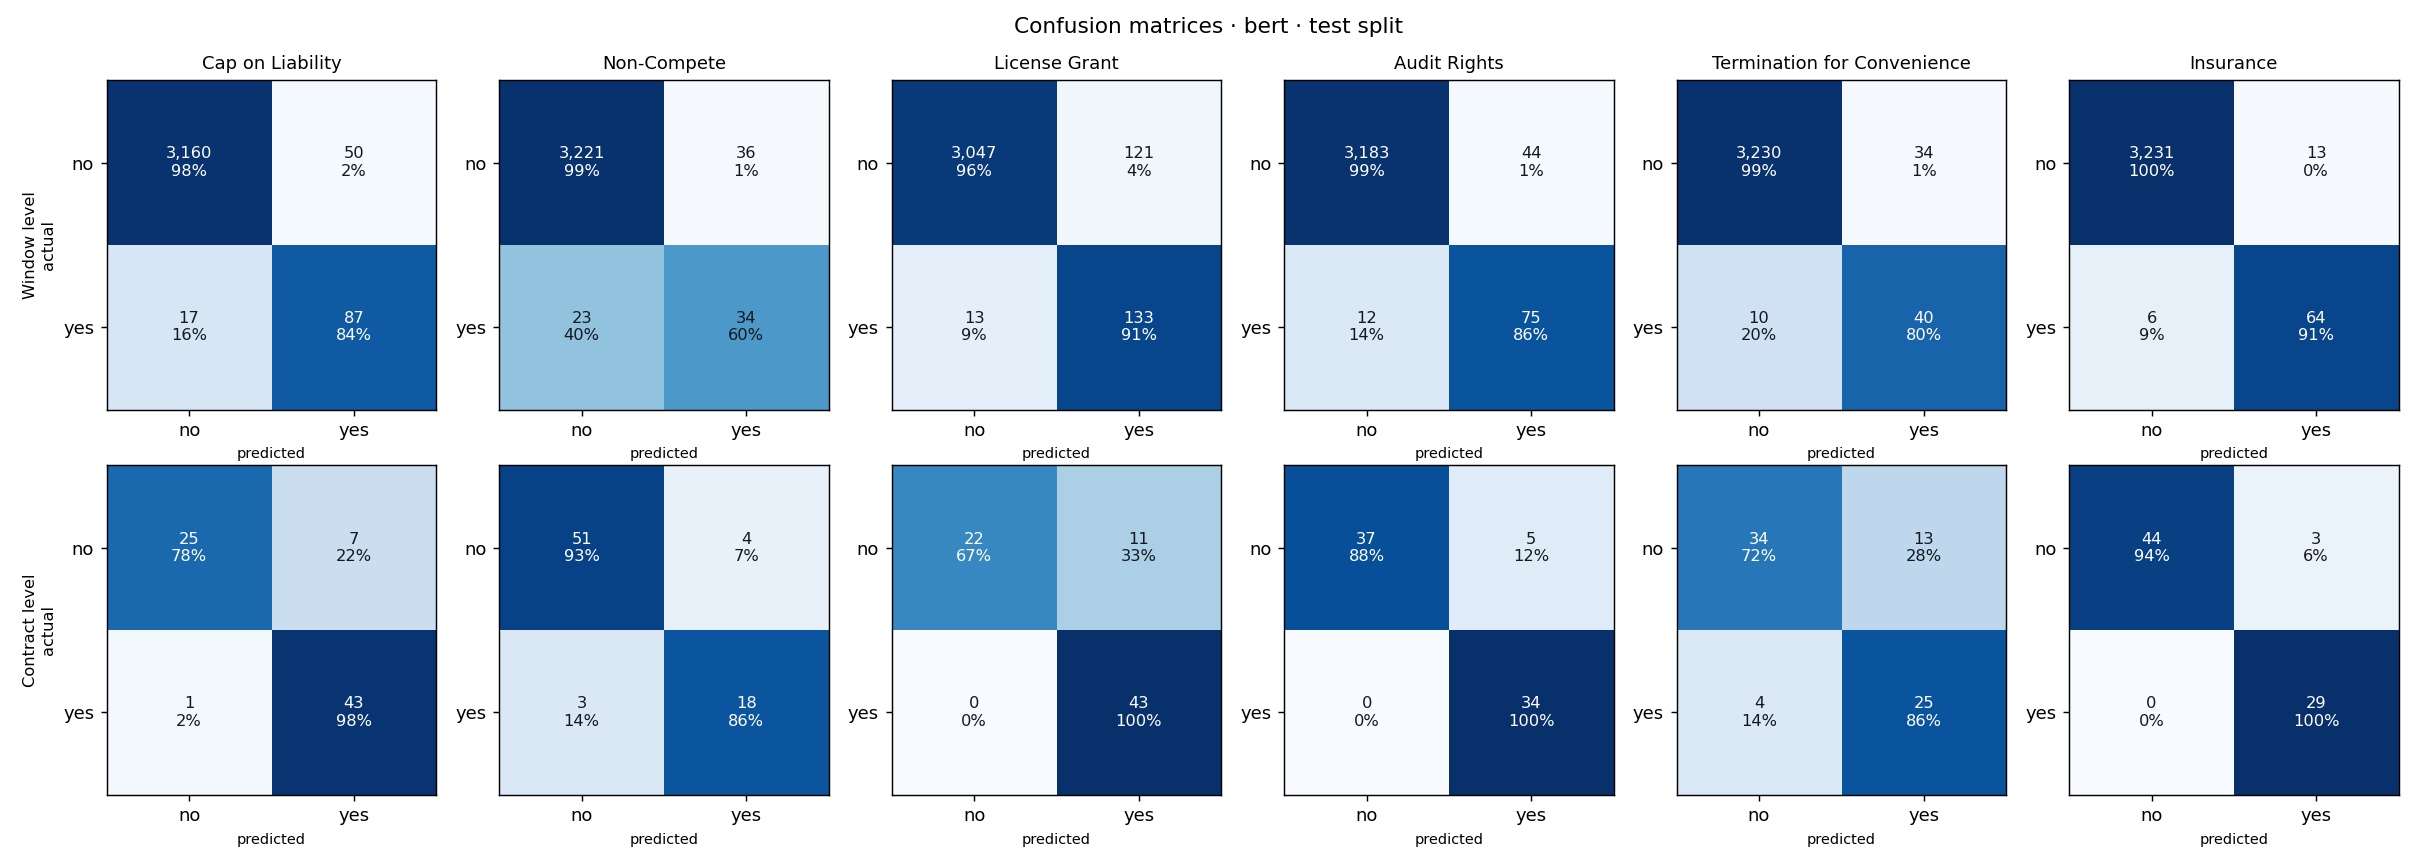

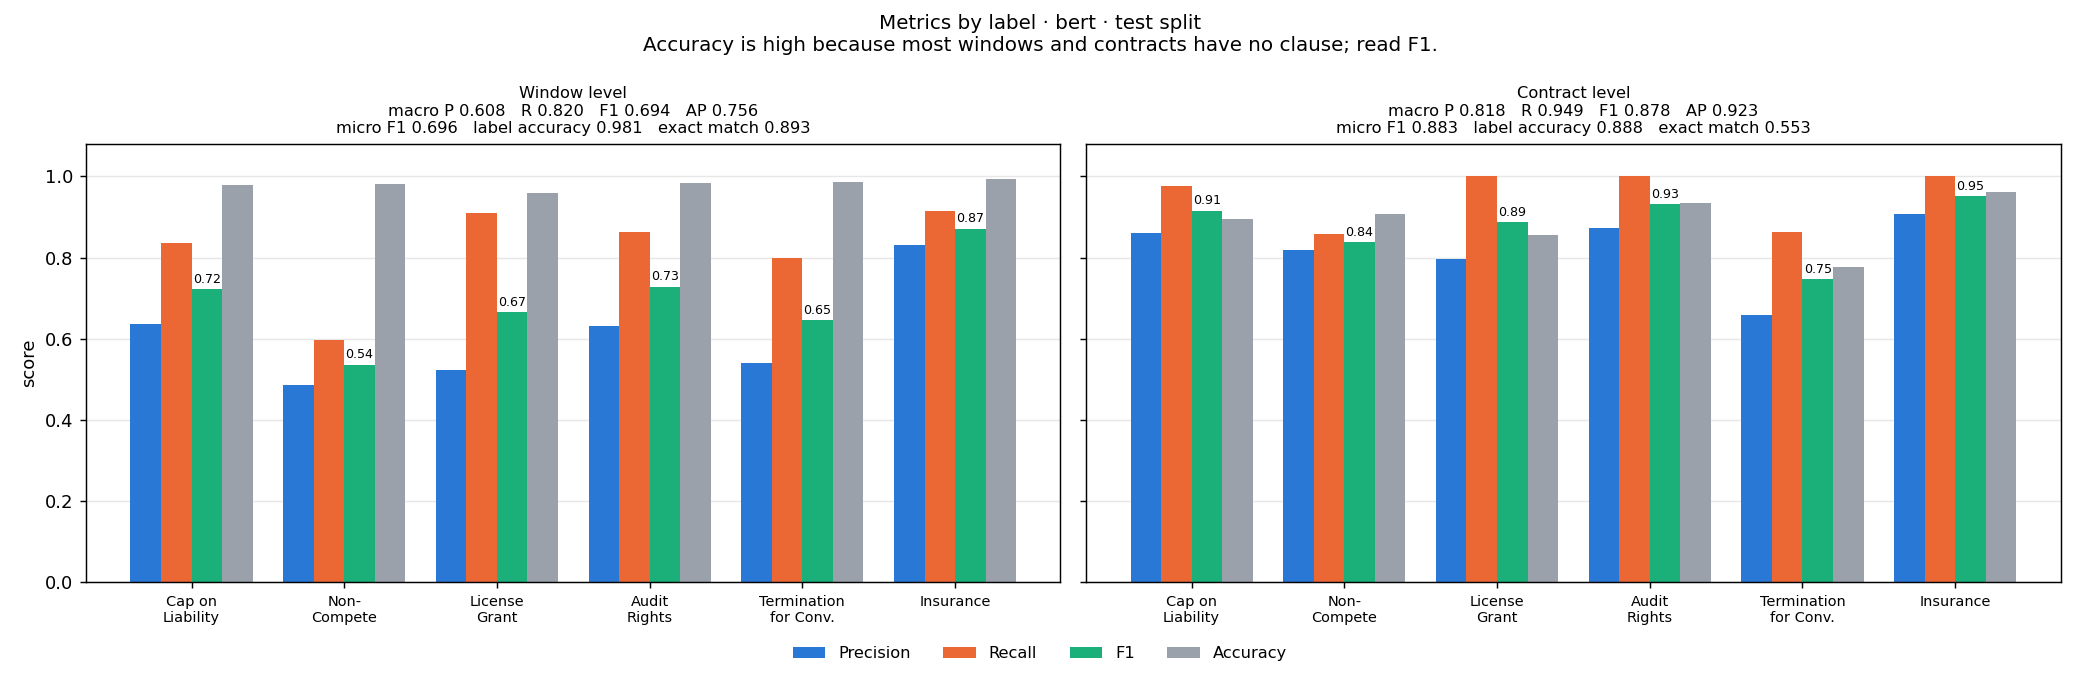

bert · test split

Window level (3314 windows of 300 words, validation-tuned thresholds)

                             precision    recall  f1-score   support

           Cap on Liability      0.711     0.827     0.764       104
                Non-Compete      0.659     0.509     0.574        57
              License Grant      0.755     0.801     0.777       146
               Audit Rights      0.631     0.885     0.737        87
Termination for Convenience      0.424     0.840     0.564        50
                  Insurance      0.847     0.871     0.859        70

                  micro avg      0.672     0.802     0.731       514
                  macro avg      0.671     0.789     0.713       514
               weighted avg      0.695     0.802     0.736       514
                samples avg      0.118     0.118     0.117       514
Samples avg scores each window over its own labels, so the many windows with no
clause count as zero here. Read the per-class rows and the macro aver

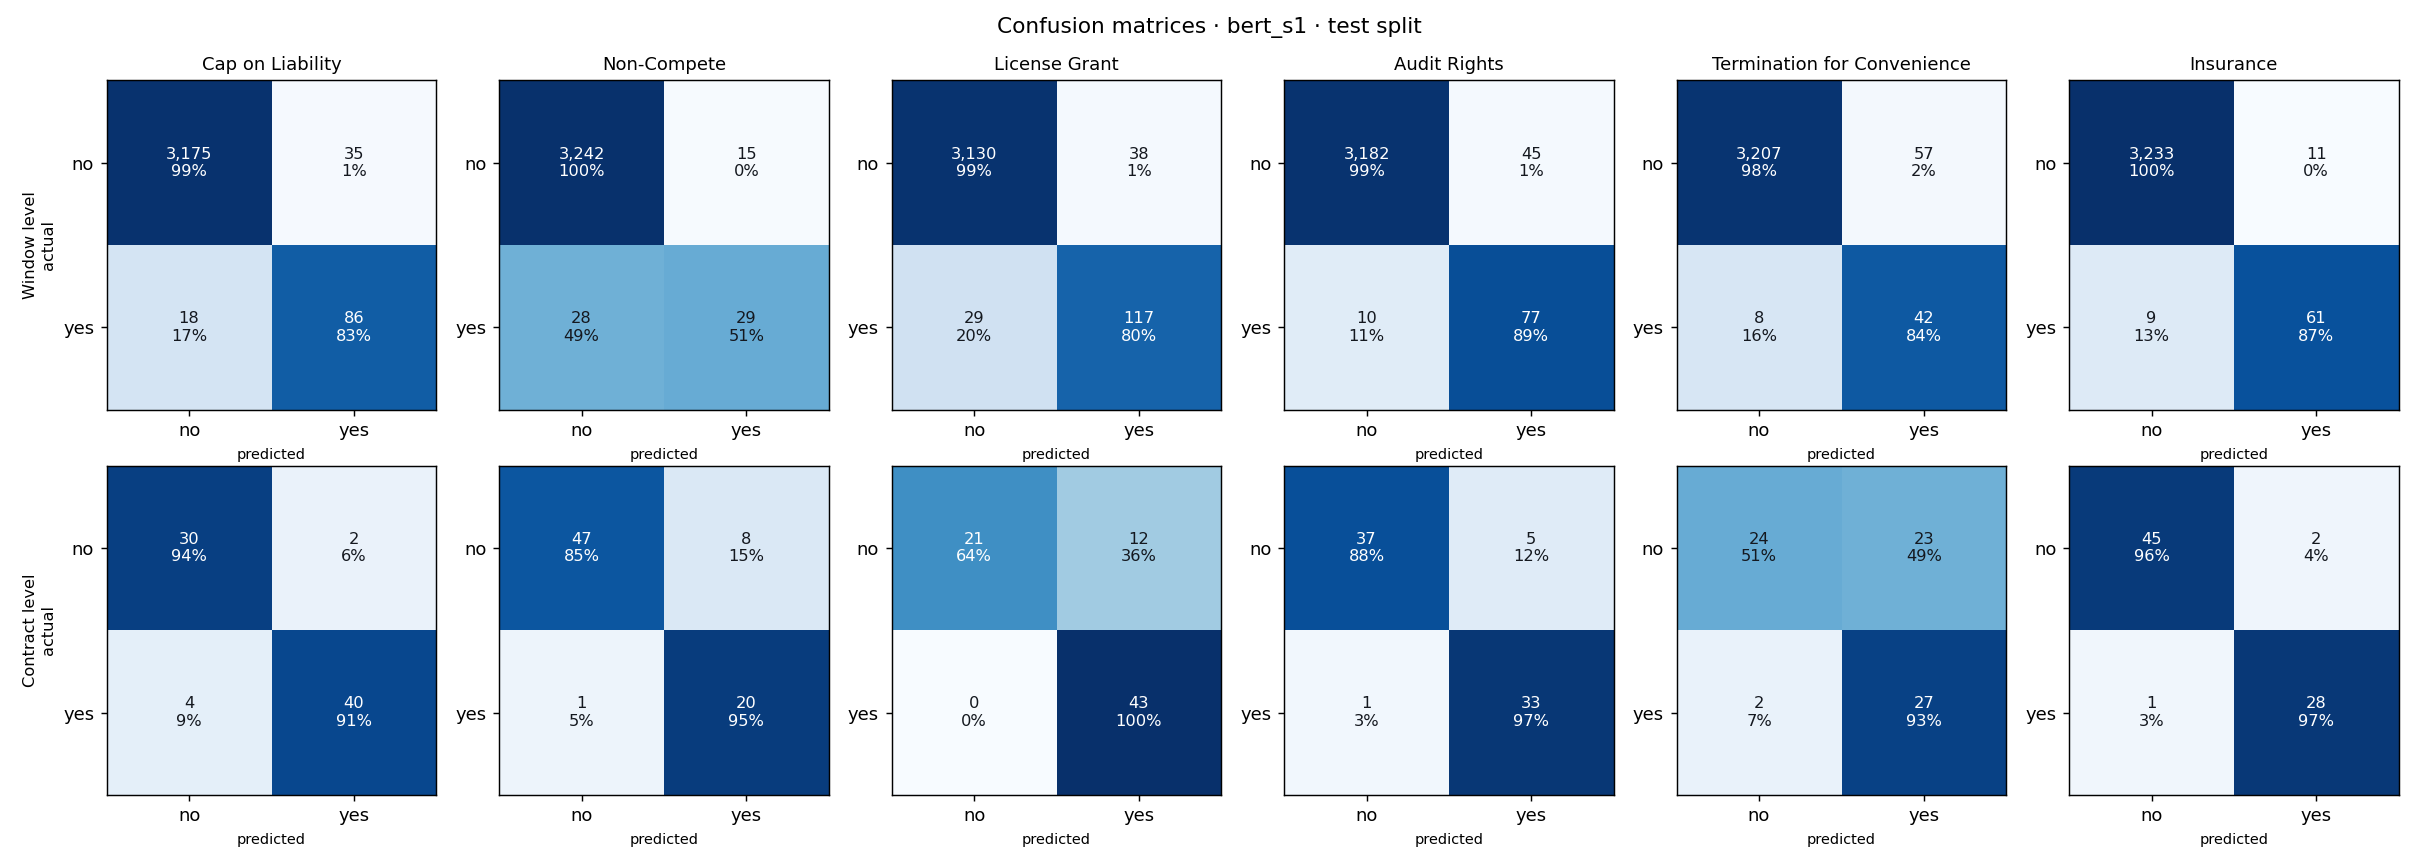

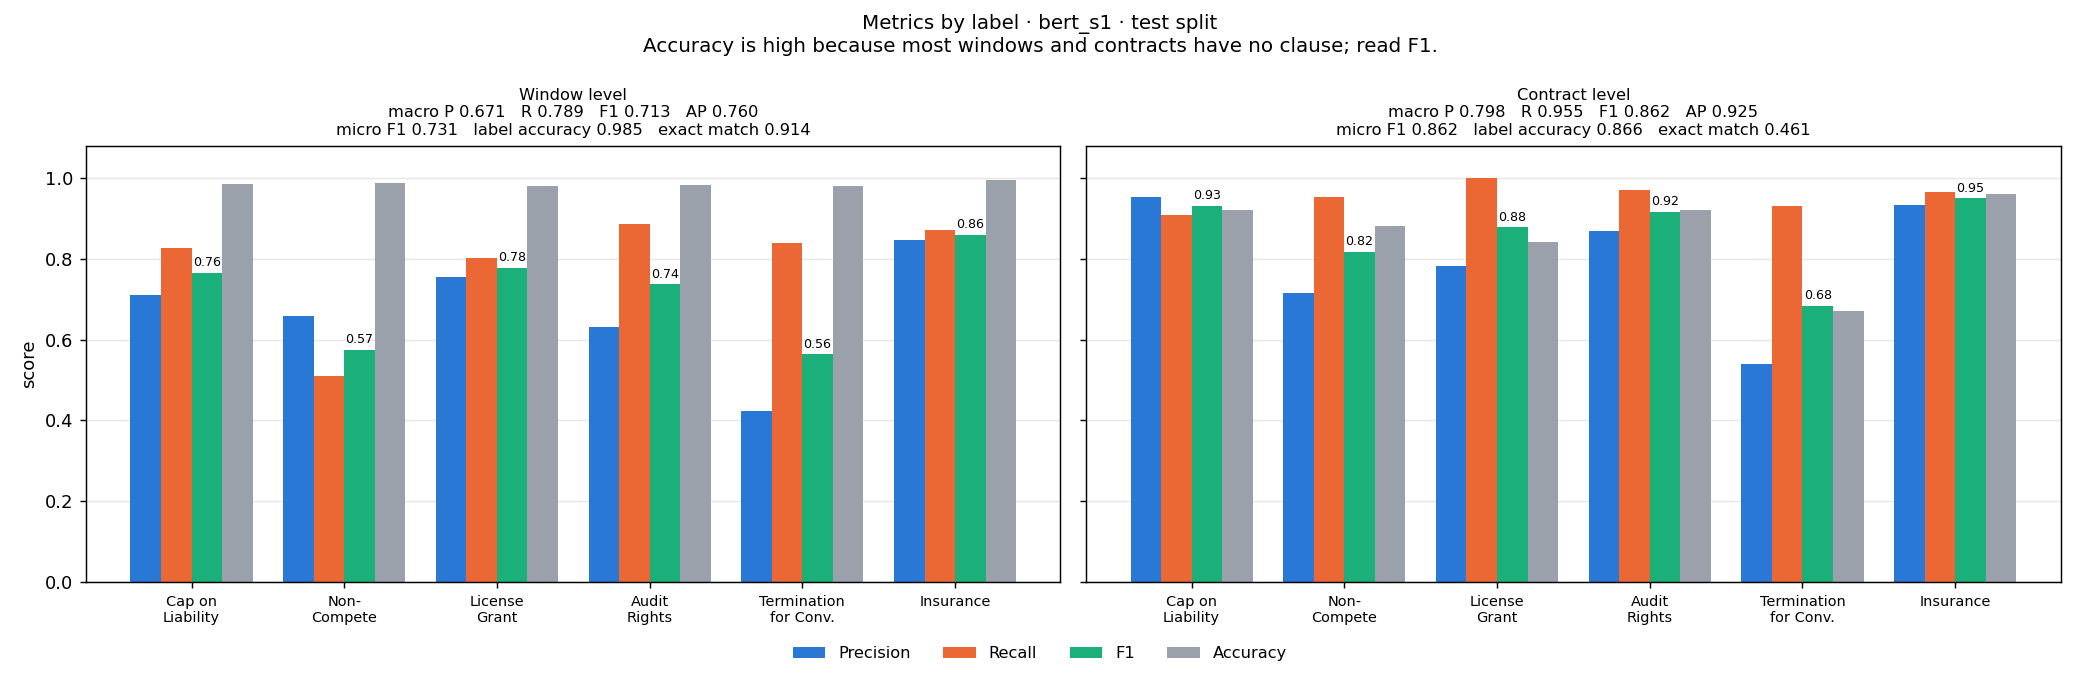

bert · test split

Window level (3314 windows of 300 words, validation-tuned thresholds)

                             precision    recall  f1-score   support

           Cap on Liability      0.755     0.712     0.733       104
                Non-Compete      0.462     0.632     0.533        57
              License Grant      0.760     0.801     0.780       146
               Audit Rights      0.564     0.862     0.682        87
Termination for Convenience      0.424     0.780     0.549        50
                  Insurance      0.785     0.886     0.832        70

                  micro avg      0.636     0.784     0.702       514
                  macro avg      0.625     0.779     0.685       514
               weighted avg      0.663     0.784     0.711       514
                samples avg      0.119     0.116     0.117       514
Samples avg scores each window over its own labels, so the many windows with no
clause count as zero here. Read the per-class rows and the macro aver

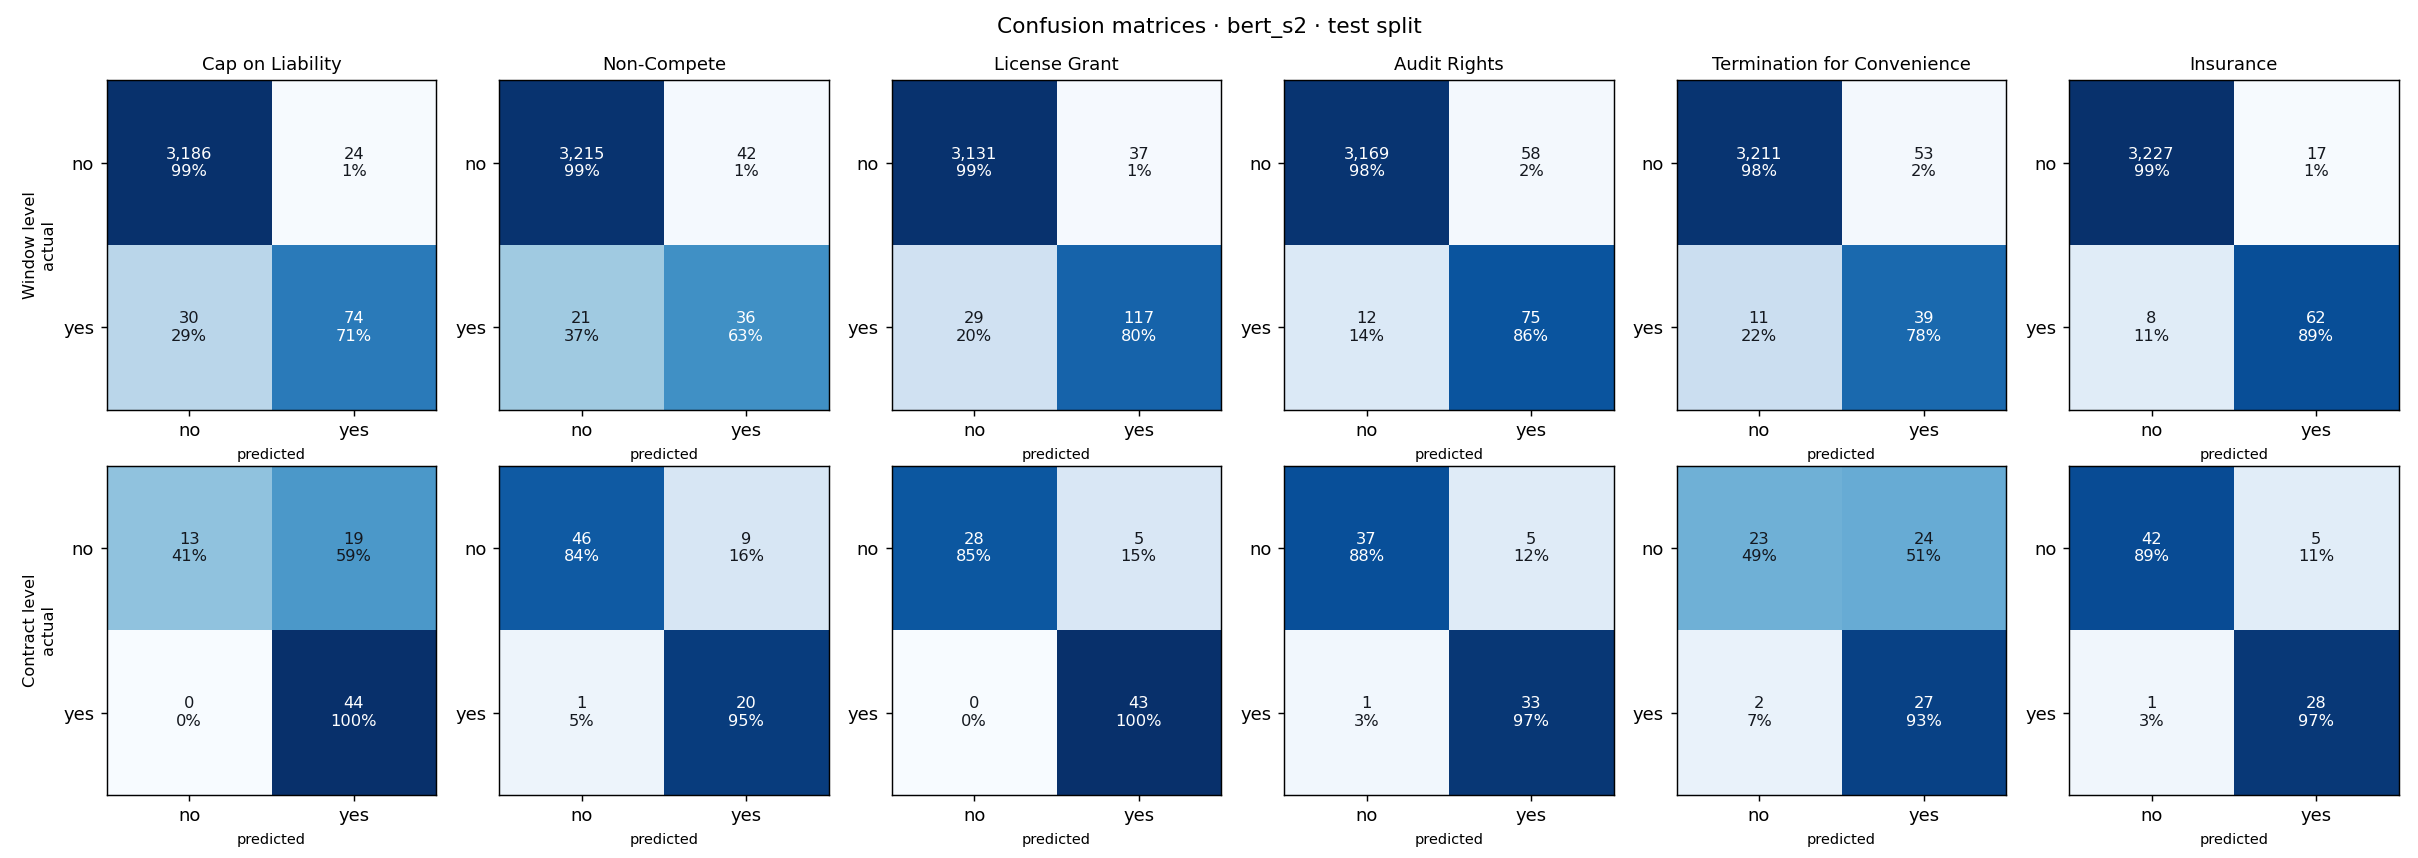

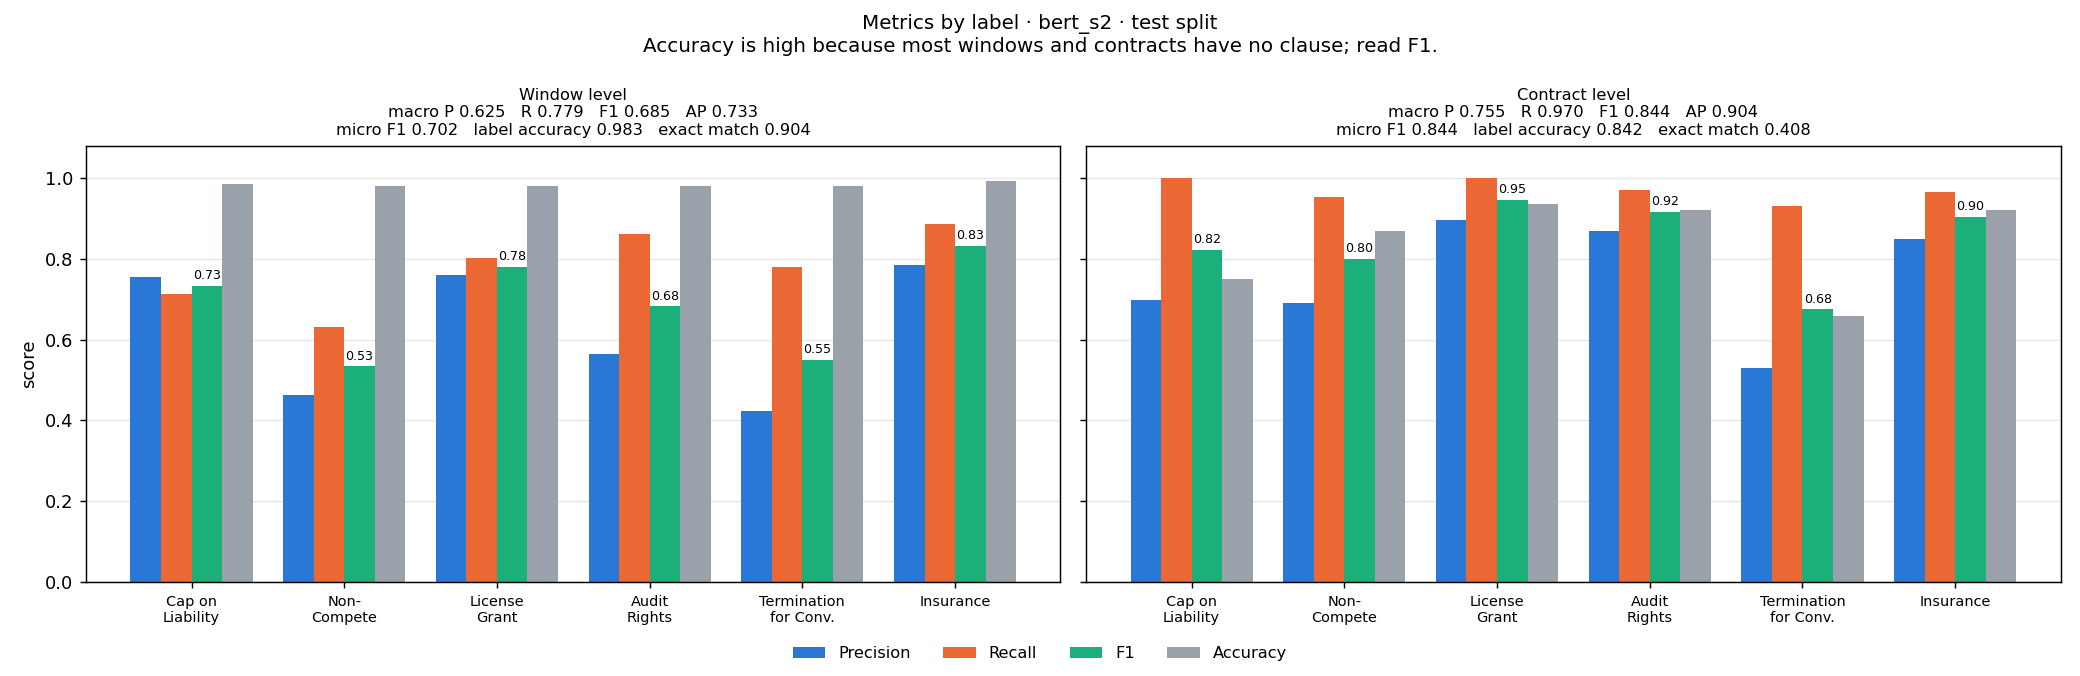

textcnn · test split

Window level (3314 windows of 300 words, validation-tuned thresholds)

                             precision    recall  f1-score   support

           Cap on Liability      0.784     0.731     0.756       104
                Non-Compete      0.516     0.281     0.364        57
              License Grant      0.700     0.815     0.753       146
               Audit Rights      0.547     0.874     0.673        87
Termination for Convenience      0.462     0.480     0.471        50
                  Insurance      0.797     0.843     0.819        70

                  micro avg      0.657     0.720     0.687       514
                  macro avg      0.634     0.670     0.639       514
               weighted avg      0.661     0.720     0.678       514
                samples avg      0.109     0.106     0.107       514
Samples avg scores each window over its own labels, so the many windows with no
clause count as zero here. Read the per-class rows and the macro a

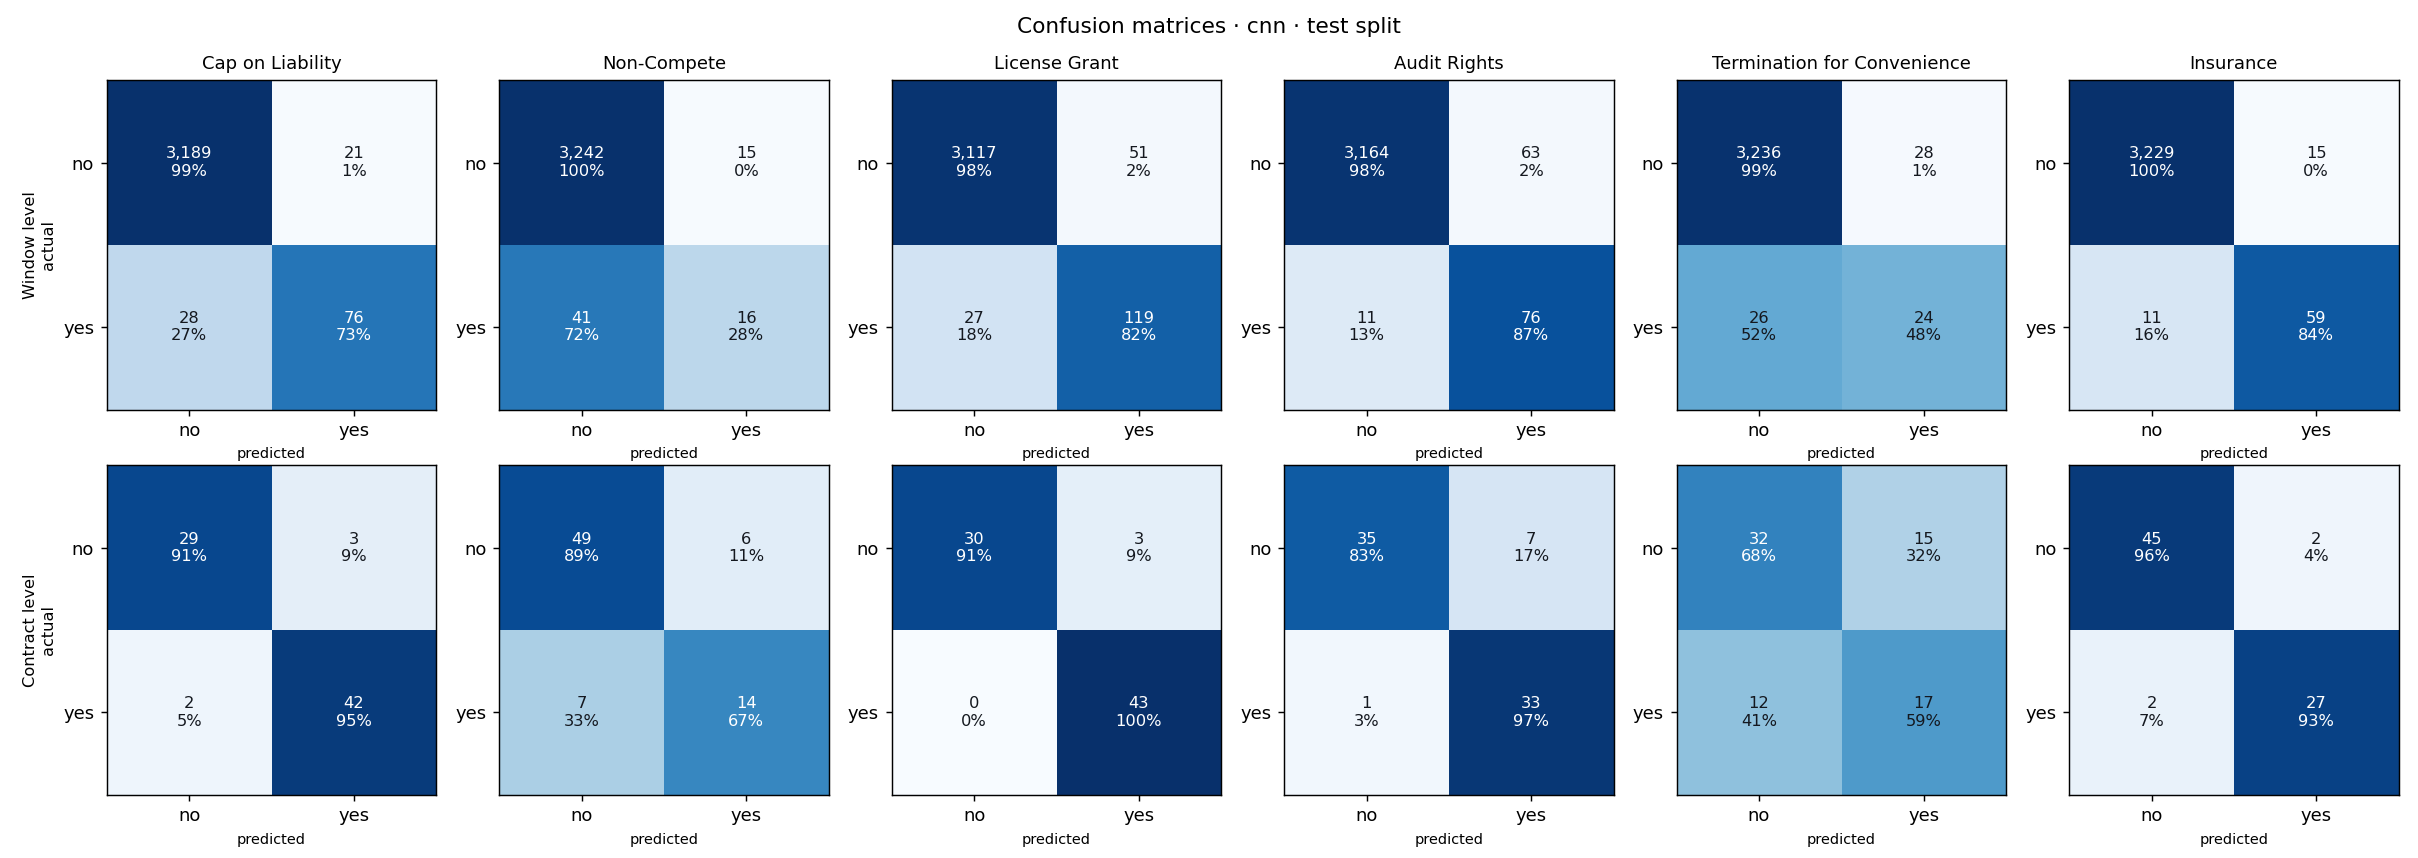

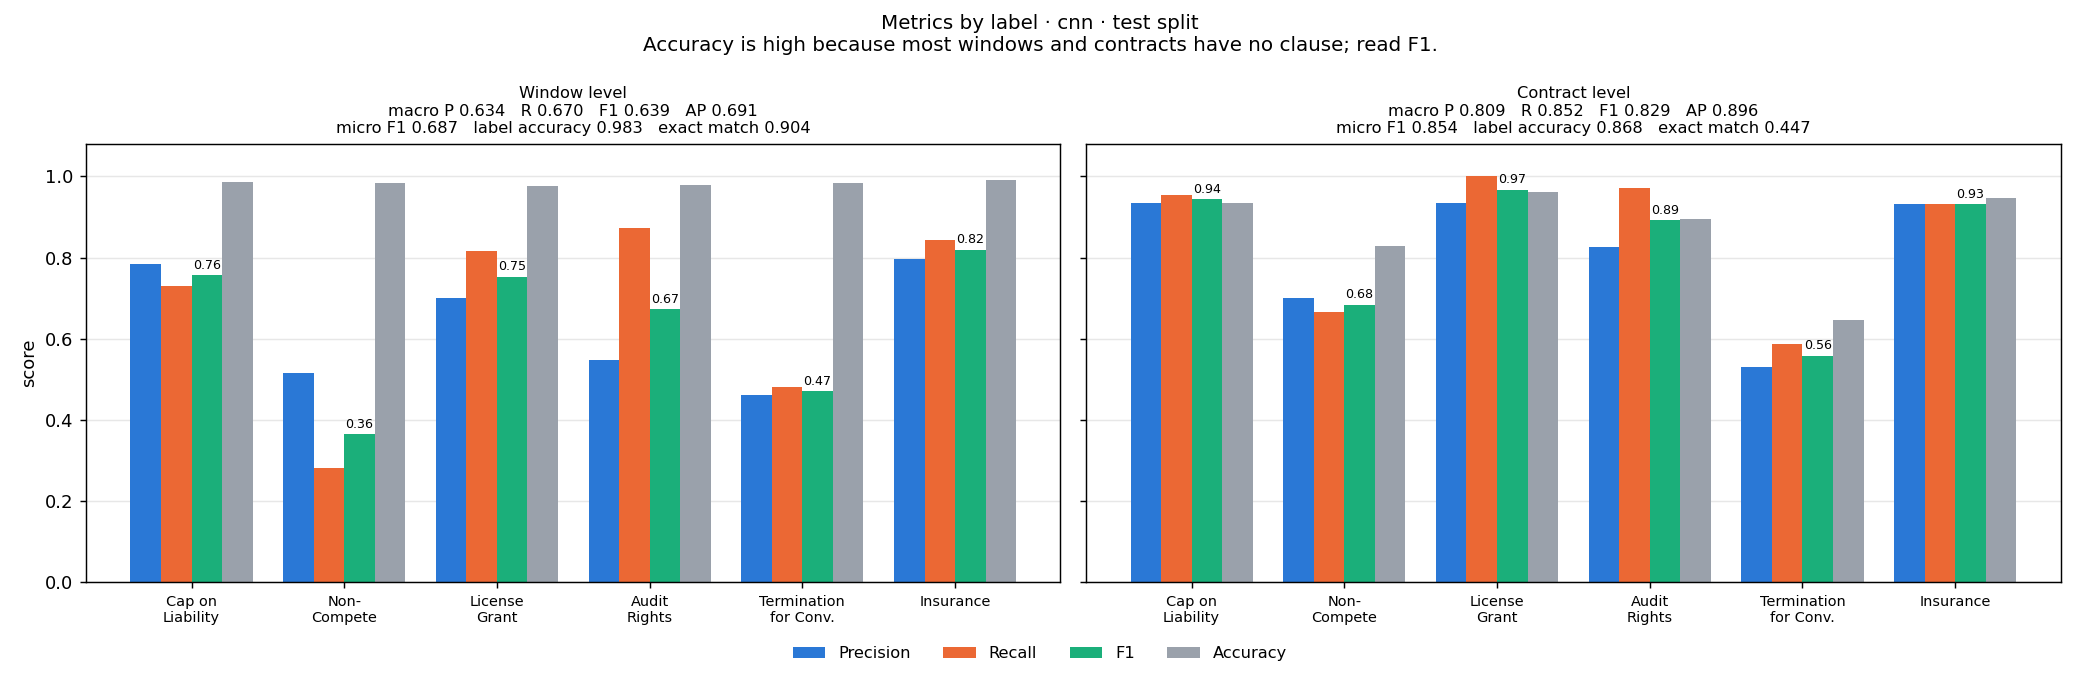

legal-bert · test split

Window level (3314 windows of 300 words, validation-tuned thresholds)

                             precision    recall  f1-score   support

           Cap on Liability      0.796     0.827     0.811       104
                Non-Compete      0.600     0.474     0.529        57
              License Grant      0.795     0.795     0.795       146
               Audit Rights      0.629     0.897     0.739        87
Termination for Convenience      0.773     0.680     0.723        50
                  Insurance      0.795     0.886     0.838        70

                  micro avg      0.739     0.784     0.761       514
                  macro avg      0.731     0.760     0.739       514
               weighted avg      0.743     0.784     0.758       514
                samples avg      0.119     0.116     0.117       514
Samples avg scores each window over its own labels, so the many windows with no
clause count as zero here. Read the per-class rows and the macr

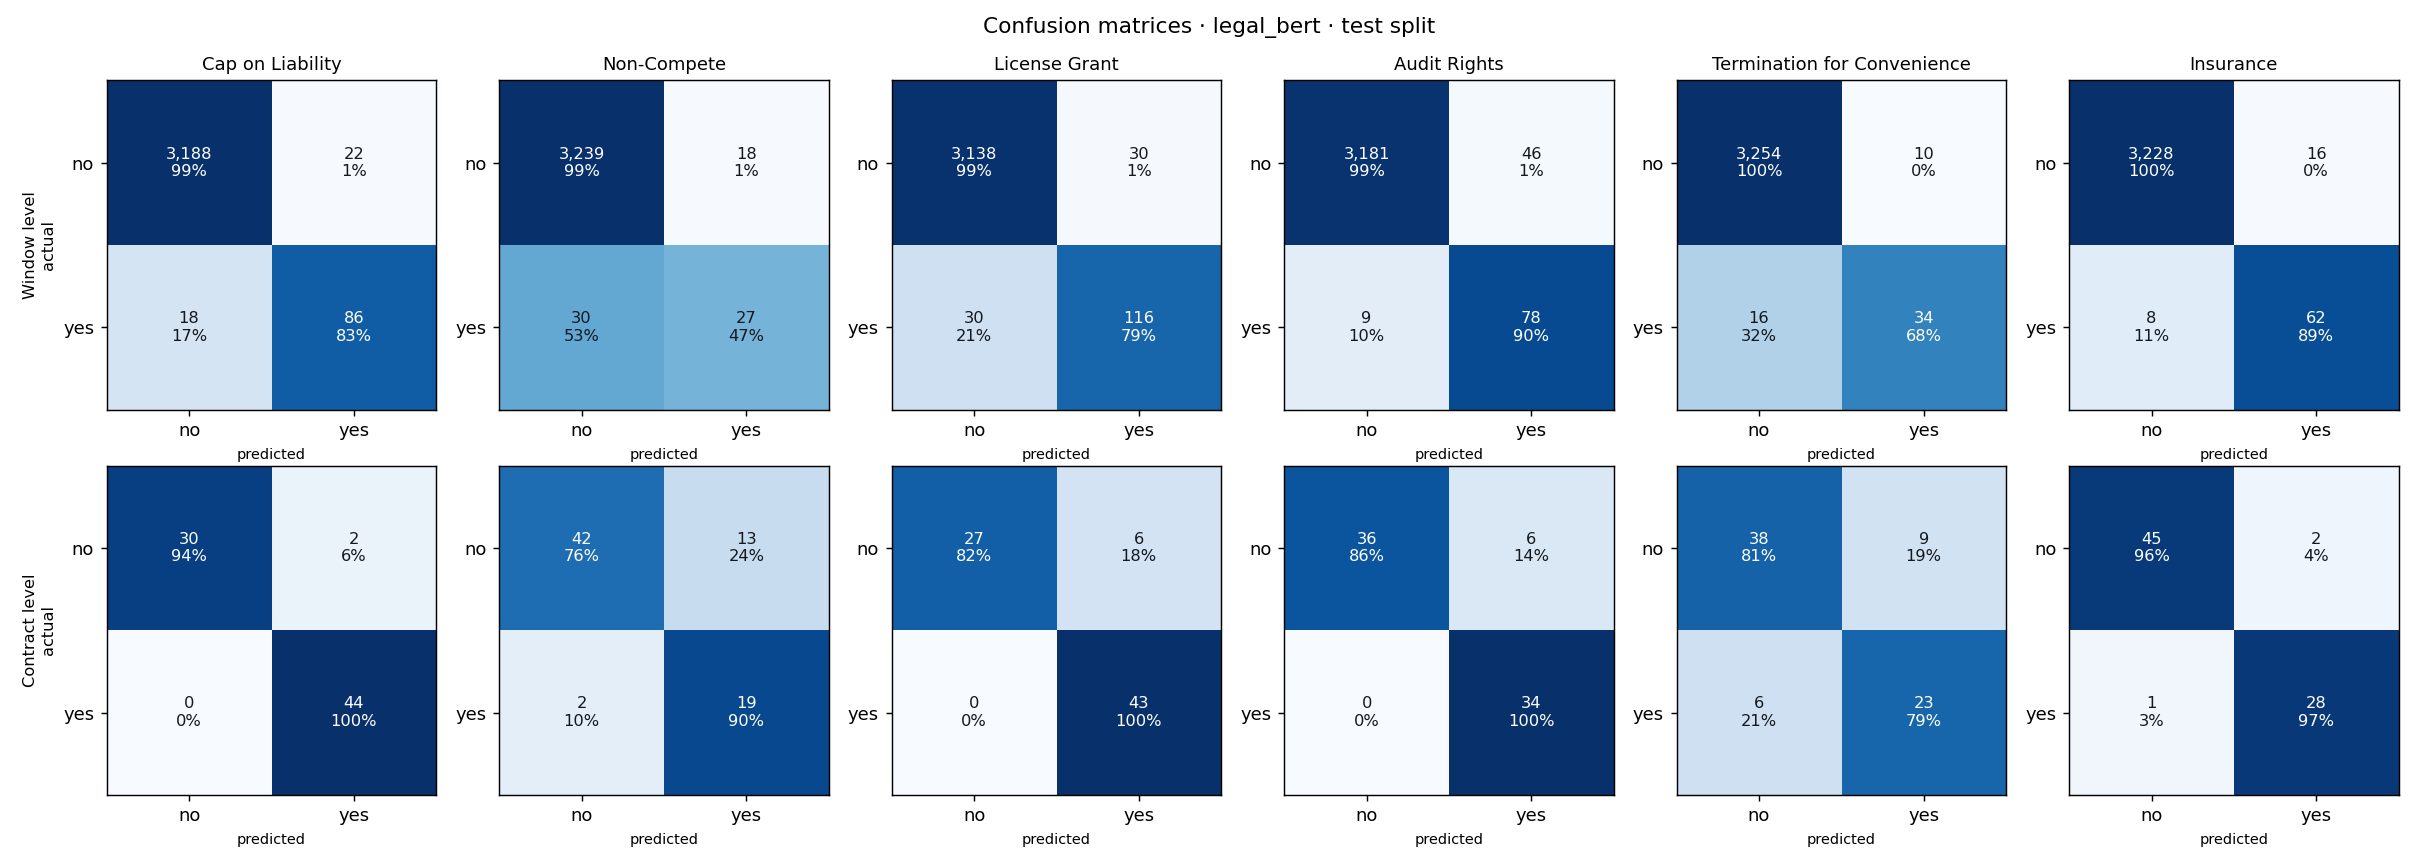

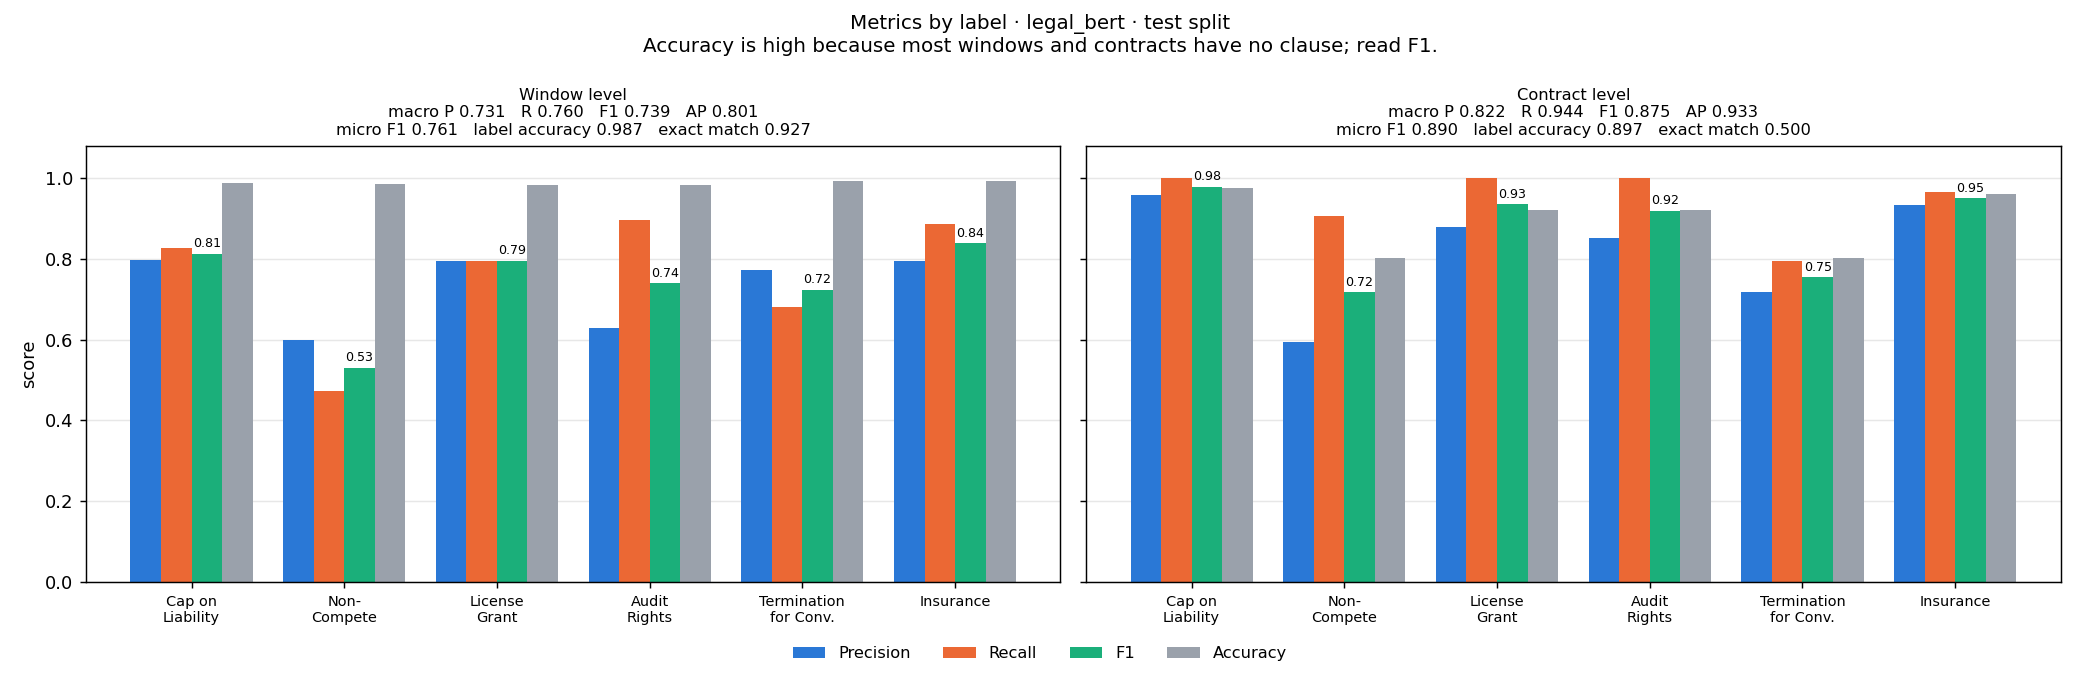

legal-bert · test split

Window level (3314 windows of 300 words, validation-tuned thresholds)

                             precision    recall  f1-score   support

           Cap on Liability      0.728     0.875     0.795       104
                Non-Compete      0.521     0.667     0.585        57
              License Grant      0.848     0.767     0.806       146
               Audit Rights      0.702     0.839     0.764        87
Termination for Convenience      0.551     0.860     0.672        50
                  Insurance      0.851     0.900     0.875        70

                  micro avg      0.717     0.817     0.764       514
                  macro avg      0.700     0.818     0.749       514
               weighted avg      0.734     0.817     0.768       514
                samples avg      0.123     0.120     0.121       514
Samples avg scores each window over its own labels, so the many windows with no
clause count as zero here. Read the per-class rows and the macr

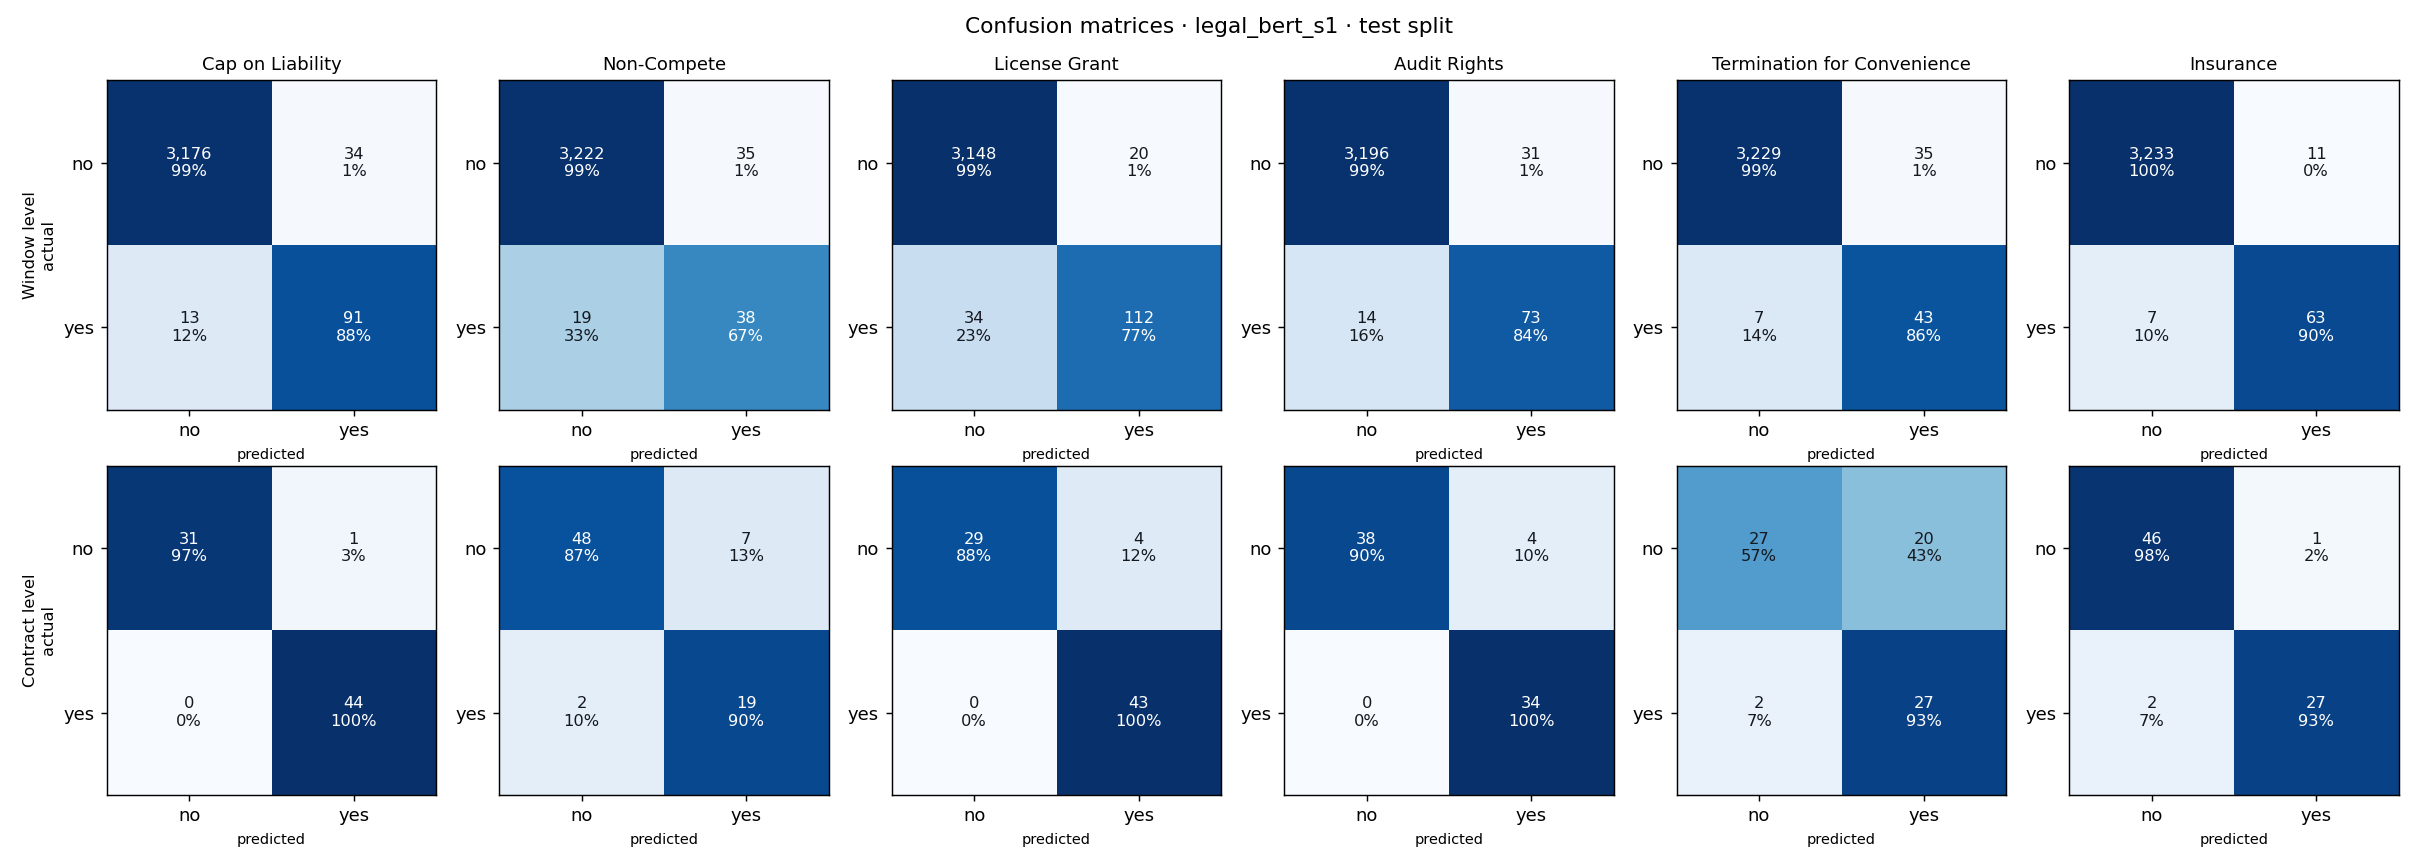

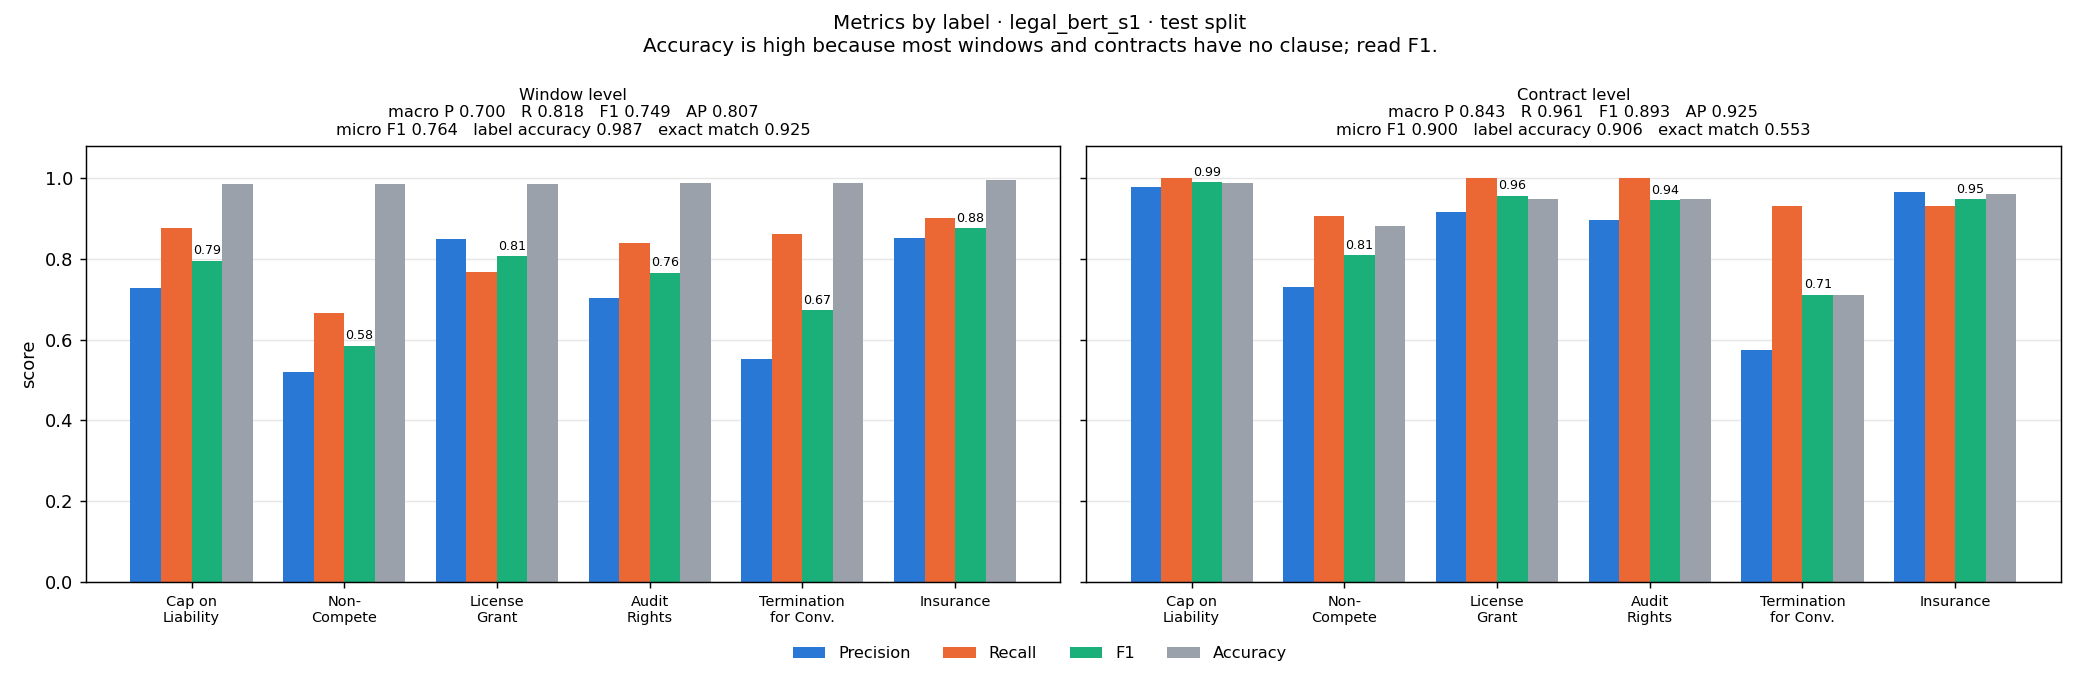

legal-bert · test split

Window level (3314 windows of 300 words, validation-tuned thresholds)

                             precision    recall  f1-score   support

           Cap on Liability      0.853     0.837     0.845       104
                Non-Compete      0.554     0.719     0.626        57
              License Grant      0.793     0.788     0.790       146
               Audit Rights      0.563     0.920     0.699        87
Termination for Convenience      0.575     0.840     0.683        50
                  Insurance      0.800     0.857     0.828        70

                  micro avg      0.696     0.827     0.756       514
                  macro avg      0.690     0.827     0.745       514
               weighted avg      0.720     0.827     0.762       514
                samples avg      0.124     0.122     0.122       514
Samples avg scores each window over its own labels, so the many windows with no
clause count as zero here. Read the per-class rows and the macr

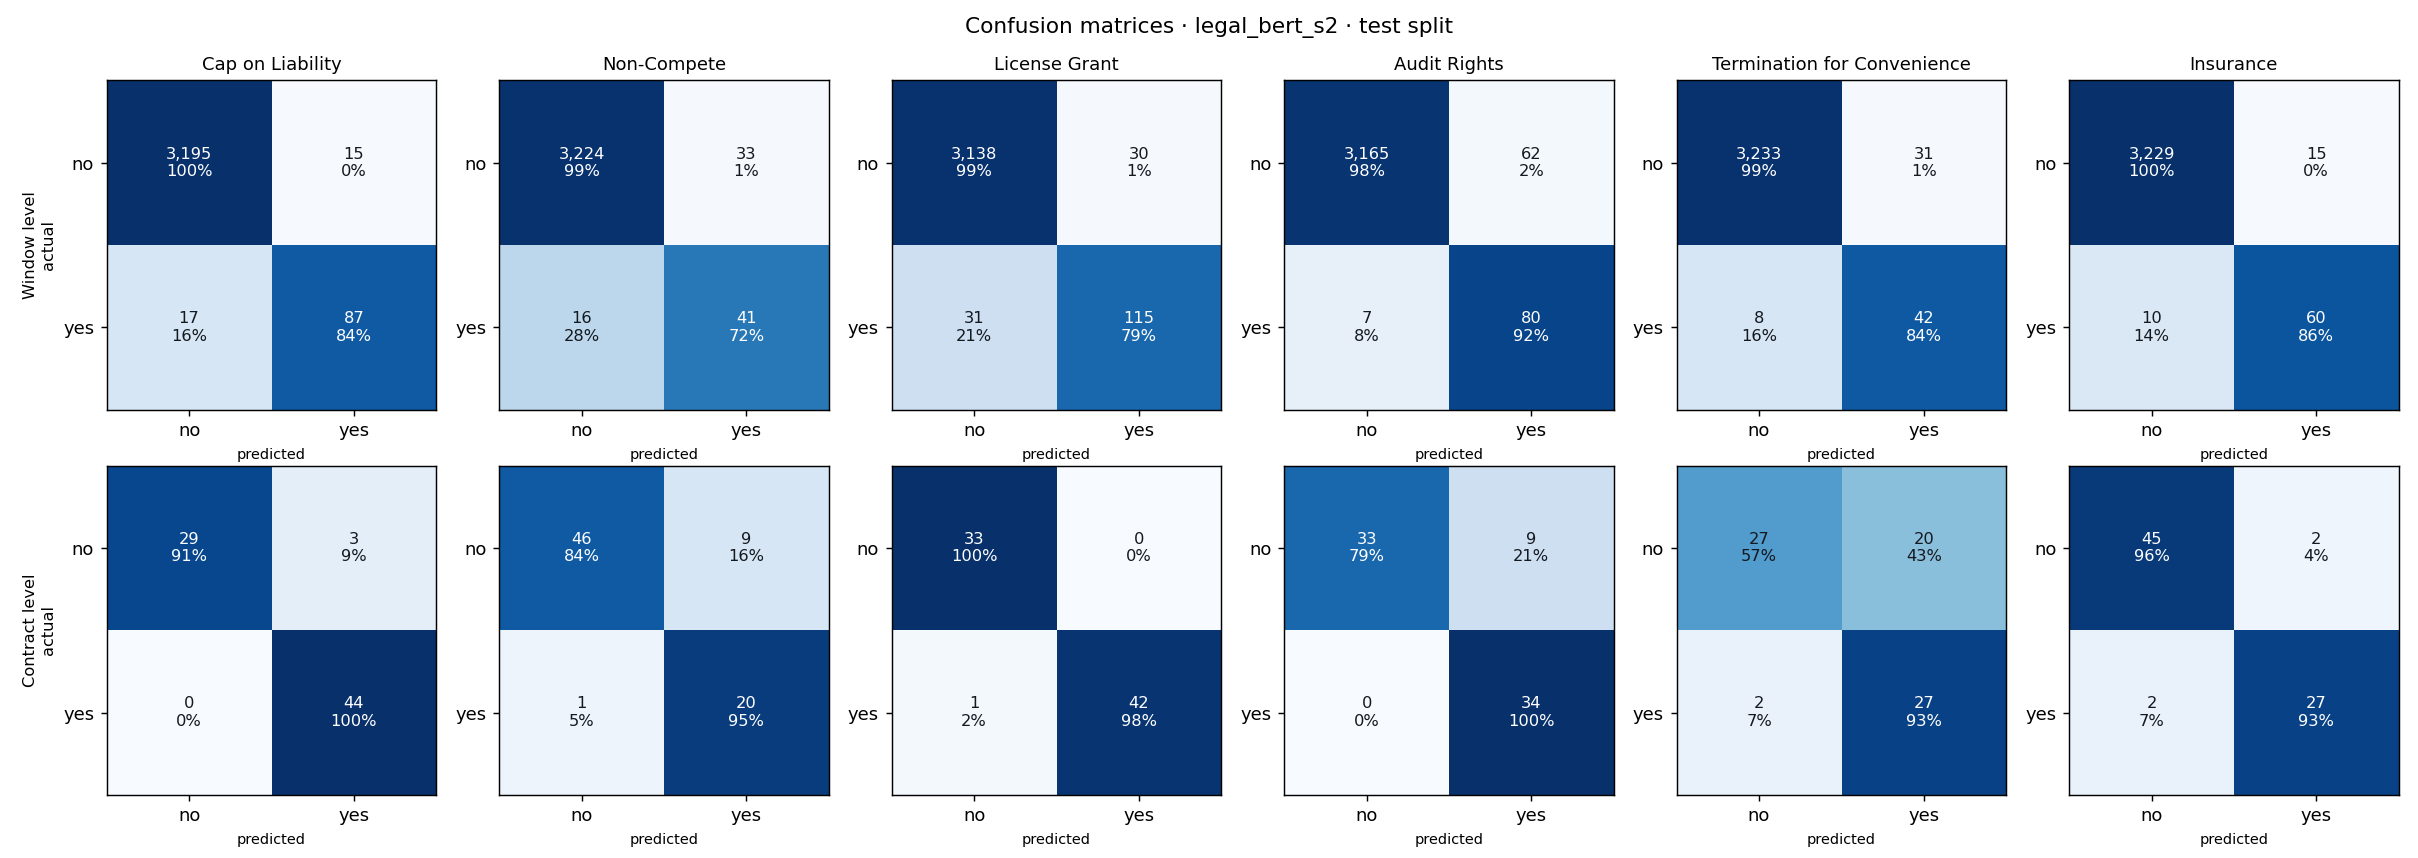

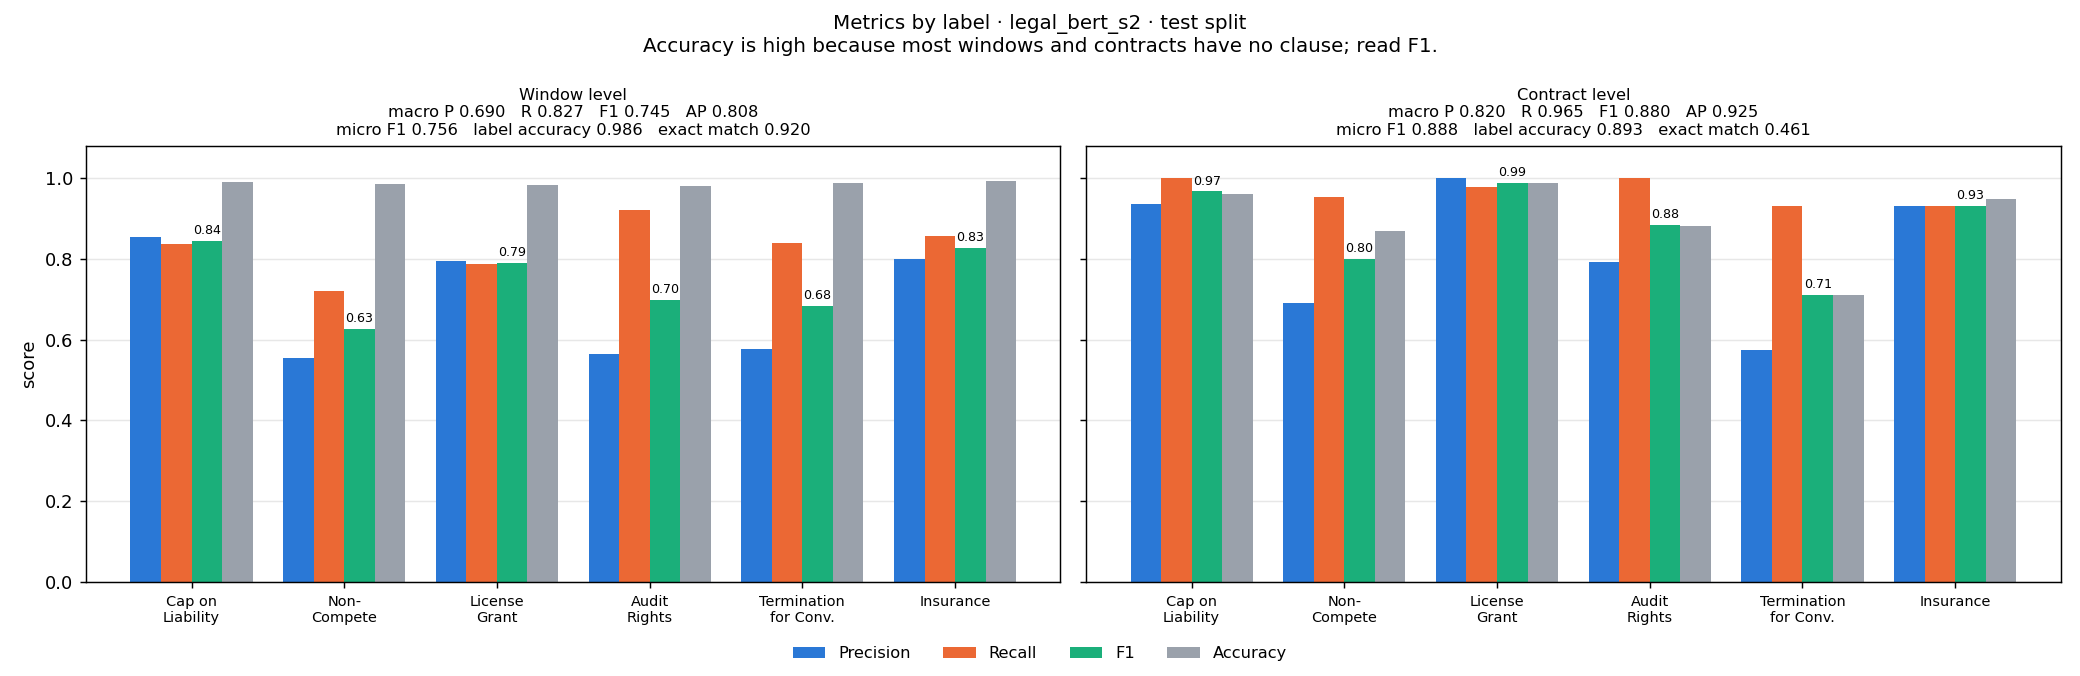

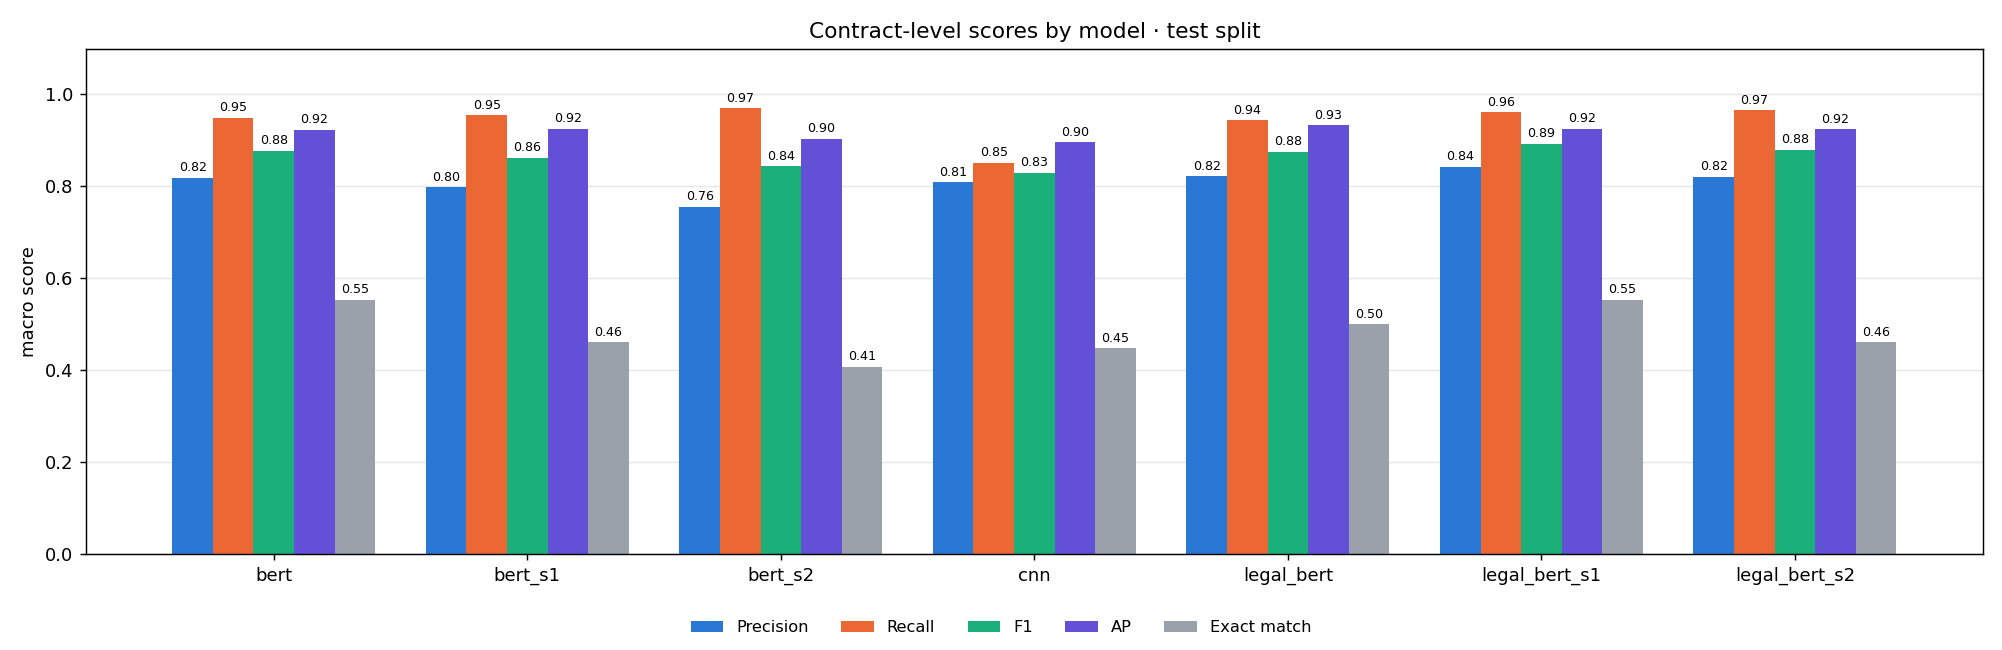

In [9]:
# Plots for every evaluated run: confusion matrices, then precision, recall, F1 and
# accuracy by label, then all runs side by side. Saved as PNGs in each run folder.
import pathlib
from IPython.display import Image, display
from legal_risk_classifier.plots import plot_run, plot_comparison

runs = sorted(path.parent for path in pathlib.Path('outputs').glob('*/evaluation_test.json'))
for run in runs:
    print('=' * 78)
    print((run / 'classification_report_test.txt').read_text())
    for png in plot_run(run, show=False):
        display(Image(str(png)))
display(Image(str(plot_comparison(runs, show=False))))